# Module 2 — Embeddings

Part of the RAG Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

**Where this module starts**
- RAG (retrieval-augmented generation) answers a question in two steps:
  1. A search program finds the few documents in a collection that match the question.
  2. A language model, the kind of program behind chat assistants, reads those documents and writes the answer.
- To find the matching documents, the search has to compare the question with every document in the collection, for every new question.
- Checking whether two texts share words is easy for a computer, but two texts can say the same thing in different words. So the search turns each document once, when the collection is stored, into a list of numbers built to be similar for texts with similar meaning. For each new question, it turns the question into a list of numbers the same way, and compares the lists. Comparing two lists of numbers is simple arithmetic, which a computer does in a tiny fraction of a second.
- That list of numbers is called an **embedding**. The program that makes it is called an **embedding model**.
- The search works only if texts with similar meaning really do get similar lists. How to measure "similar" is part of this module.

**This module's point:** A RAG system is built from five parts:
1. Chunk: split each document into short pieces
2. **Embed**: turn each piece into a list of numbers
3. Store: keep every piece's list in one table
4. Retrieve: turn the question into a list the same way, and return the pieces whose lists are most similar
5. Generate: the language model reads those pieces and writes the answer

it builds the embedding, the piece of the search program that turns text into numbers, and measures whether texts with similar meaning get similar lists.<br>
<u>Note</u>: this module skips part 1, chunk: its texts are single sentences, already short.

**What this module tests**

The texts are sentences from news articles, taken from a public dataset called MultiHop-RAG. The dataset has questions about the articles, and for each question it lists the sentences in the articles that support its answer. Sentences listed for the same question are often about the same topic, so their embeddings should be close.

The module runs four steps:
1. Turn every listed sentence into an embedding, and look at two, the shortest sentence and the longest, to see what a list looks like: its size, its first numbers and its length.
2. Compare the sentences of three questions with each other: do sentences of the same question get closer embeddings to each other than to sentences of other questions?
3. Compare every listed sentence's embedding with every other listed sentence's embedding: do two sentences listed for the same question get closer embeddings than two sentences listed for different questions, and by how much?
4. Change four sentences by hand. Each one is reworded once, keeping its facts, and changed three times in ways that change its facts: add "not", swap a name, or change a number. Which changed sentence's embedding is closest to the original sentence's embedding?

**What this module produces**
1. A way to measure how close two embeddings are, worked by hand on a small example.
2. A comparison of how close the lists of sentences of the same question are, against sentences of different questions.
3. A test of three changes to a sentence's facts that an embedding might not notice, against a rewording that keeps the facts.

## From the curriculum

> ## <u>Module 2 — Embeddings</u>
>
> **Concepts**
> - An embedding: a piece of text turned into a fixed-length list of numbers
> - Cosine similarity: one number, from −1 to 1, for how close two embeddings are
> - Why similar meaning lands close, and where it fails (negation, names, numbers)
>
> **Worked example:** sentences from the articles, their embeddings, and which
> pairs land close.

## Lesson

### The embedding model in this module

- The embedding model is nomic-embed-text, made by Nomic AI. It runs on the laptop this playbook was built on, through Ollama, a free program that runs AI models.
- It is a separate model from the language model, and it writes no text. It reads a text and returns a list of 768 numbers.
- Every text gets a list of the same size, 768 numbers, whether it is three words or a long paragraph.

### Why texts with similar meaning get similar lists

- The embedding model was trained on millions of pairs of texts that belong together, such as a question and its answer from a question-and-answer website, or a title and the article under it, according to [Nomic AI's paper on the model](https://arxiv.org/abs/2402.01613).
- The model's list for a text is calculated from the text's tokens, the pieces of words a model reads, using the model's internal numbers: millions of settings that decide which list comes out.
- Training means adjusting those internal numbers, pair after pair, until the two texts of each pair get close lists, and texts from different pairs get distant lists.
- Texts about one topic share many tokens, such as "touchdown" and "quarterback". Because a list is calculated from the tokens, two texts that share many tokens share much of their calculation, and training made texts of one topic come out with close lists. So a new text that shares many tokens with the training texts about one topic gets a list close to those texts' lists, even though the model never saw the new text.

### Measuring how close two lists are: cosine similarity

To say whether two sentences got close lists, each pair of lists needs one number that says how close they are. That number is the **cosine similarity**.

- Picture a list of 2 numbers as an arrow drawn from a starting point: the first number says how far right the arrow goes, the second how far up.
- A list of 768 numbers is an arrow drawn with 768 such measurements instead of 2. It cannot be drawn on paper, but it still points in one direction, and the arithmetic below is the same.
- Cosine similarity says how close the directions of two arrows are:
  - 1: the same direction
  - 0: at a right angle
  - −1: opposite directions

**formula**:

Length of A = $\sqrt{\sum_{i} A_i^2}$, where $A_i$ is the i-th number of embedding A, and $\sum_{i}$ adds over i = 1 to 768

Cosine similarity of A and B = $\frac{\sum_{i} A_i \times B_i}{(\text{length of A}) \times (\text{length of B})}$, where $A_i$, $B_i$ are the i-th numbers of embeddings A, B

Why this formula measures direction:
- The sum of products, before the division, grows when the two lists have large numbers in the same positions, with the same sign: the two arrows lean the same way.
- That sum also grows when an arrow is simply longer. Dividing by the two lengths cancels that, so only the direction counts. For example, doubling every number in A doubles the sum of products and doubles A's length, so the division gives the same result.

A hand example with lists of 2 numbers, chosen for easy arithmetic: A = (3, 4), B = (4, 3) and C = (4, −3).

- Length of A = square root of ((3 × 3) + (4 × 4)) = square root of 25 = 5
- Length of B = square root of ((4 × 4) + (3 × 3)) = square root of 25 = 5
- Length of C = square root of ((4 × 4) + ((−3) × (−3))) = square root of 25 = 5

<!-- -->

- Cosine similarity of A and B = ((3 × 4) + (4 × 3)) / (5 × 5) = 24 / 25 = 0.96
- Cosine similarity of A and C = ((3 × 4) + (4 × (−3))) / (5 × 5) = 0 / 25 = 0
- Cosine similarity of B and C = ((4 × 4) + (3 × (−3))) / (5 × 5) = 7 / 25 = 0.28

The code below draws the three arrows, and checks the cosine similarity function used in this module against the example above: A and B point in nearly the same direction, and A and C at a right angle. `common` is this playbook's shared helper file: it loads the data, calls the models, and prints tables.

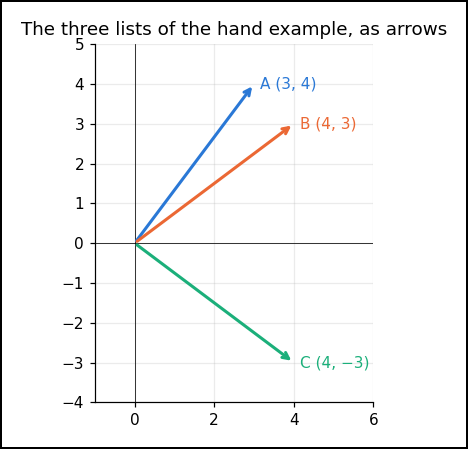

Cosine similarity of A and B = 0.96
Cosine similarity of A and C = 0.00
Cosine similarity of B and C = 0.28


In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common
from common import show, BLUE, ORANGE, AQUA


def cosine(a, b):
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))


A, B, C = np.array([3, 4]), np.array([4, 3]), np.array([4, -3])

fig, ax = plt.subplots(figsize=(4, 4))
for name, v, color in [("A (3, 4)", A, BLUE), ("B (4, 3)", B, ORANGE), ("C (4, −3)", C, AQUA)]:
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=color, linewidth=2))
    ax.text(v[0] + 0.15, v[1], name, color=color, va="center")
ax.set_xlim(-1, 6)
ax.set_ylim(-4, 5)
ax.set_aspect("equal")
ax.axhline(0, color="black", linewidth=0.5)
ax.axvline(0, color="black", linewidth=0.5)
ax.set_title("The three lists of the hand example, as arrows")
plt.tight_layout()
plt.show()

print(f"Cosine similarity of A and B = {cosine(A, B):.2f}")
print(f"Cosine similarity of A and C = {cosine(A, C):.2f}")
print(f"Cosine similarity of B and C = {cosine(B, C):.2f}")

## The data: sentences from news articles, grouped by question

The dataset is MultiHop-RAG (Tang and Yang, 2024):
- 609 news articles, published between September and December 2023, each labelled with one of six categories, such as sports or technology
- 2,556 questions about those articles. For 2,255 of them, the dataset lists 2 to 4 sentences from the articles that support the answer. The other 301 ask something no article answers, and list no sentences.

This module uses only the listed sentences. Each one is short, about 25 words (printed below), so each is about one or two things, and a comparison of two sentences is easy to read.

The dataset reuses many sentences across questions, so the code counts each unique sentence once.

In [2]:
questions = common.load_questions()

rows = [(q, e["fact"], e["title"], e["category"])
        for q, listed in questions["evidence_list"].items() for e in listed]
listed = pd.DataFrame(rows, columns=["question", "sentence", "article", "category"])
sentences = listed.drop_duplicates("sentence").reset_index(drop=True)

print(f"Questions = {len(questions):,}")
print(f"Sentences listed, over all questions = {len(listed):,}")
print(f"Unique sentences = {len(sentences):,}")
print(f"Words per sentence, median = {sentences['sentence'].str.split().str.len().median():.0f}")

Questions = 2,556
Sentences listed, over all questions = 6,084
Unique sentences = 981
Words per sentence, median = 25


## Step 1 of 4: turn every sentence into an embedding

Every comparison below needs the embeddings, so all the unique sentences are turned into embeddings first.

**The label in front of each text:** nomic-embed-text was trained with a short label in front of every text, saying what the text is for: "search_query: " in front of a question, and "search_document: " in front of a passage to be searched. Because the model was trained with these labels, its makers ask for the same labels when it is used. Every text in this module is a sentence from an article, so each one gets "search_document: ".

The result is a table of numbers: one row per sentence, 768 numbers per row.

In [3]:
vectors = common.embed(sentences["sentence"].tolist(), prefix="search_document: ")
print(f"Table of embeddings = {vectors.shape[0]:,} rows (sentences) × {vectors.shape[1]} numbers")
print()

words = sentences["sentence"].str.split().str.len()
for name, i in [("Shortest sentence", words.idxmin()), ("Longest sentence", words.idxmax())]:
    print(f"{name}, {words[i]} words:")
    print(f"  {sentences['sentence'][i]}")
    print(f"  First 5 numbers = {', '.join(f'{v:.3f}' for v in vectors[i][:5])}")
    print(f"  Length of its list = {np.linalg.norm(vectors[i]):.3f}")
    print()

lengths = np.linalg.norm(vectors, axis=1)
print(f"Length of the list, over all {len(vectors):,} sentences = {lengths.min():.3f} to {lengths.max():.3f}")

Table of embeddings = 981 rows (sentences) × 768 numbers

Shortest sentence, 11 words:
  “She’s my first wife, my only wife,” Alexander reportedly told security.
  First 5 numbers = 0.007, 0.003, -0.158, -0.032, 0.070
  Length of its list = 1.000

Longest sentence, 78 words:
  Turmoil at Flexport: Dave Clark, the former Amazon executive who was ousted as CEO of Flexport just a year into the job, fired back at its founder and board, calling recent reporting on the logistics company “deeply concerning.” Clark made the comments Monday in a lengthy post on social media site X following a report from CNBC that provided new information about his last days at Flexport, a freight forwarding and customs brokerage startup valued at $8 billion.
  First 5 numbers = 0.016, 0.070, -0.222, -0.027, 0.055
  Length of its list = 1.000

Length of the list, over all 981 sentences = 1.000 to 1.000


<u>Note</u>: not every embedding model returns embeddings of length 1. Here, Ollama, the program that runs nomic-embed-text, scales every embedding it returns to length 1. The cosine formula divides by the two lengths, so its result is the same either way.

**Observation:** an 11-word sentence and a 78-word sentence each became a list of 768 numbers.

**Observation:** every list has a length of 1, rounded to three decimals: Ollama returns them that way. So in this module, two lists can differ only in direction, and cosine similarity captures all of their difference.

No single number in a list has a meaning a person can name, such as "sports": training adjusted the model toward close lists for whole texts that belong together, never toward one number per topic. Only comparing two lists says something.

## Step 2 of 4: the sentences of three questions, compared with each other

Before measuring all sentences at once, a small example shows what to look for. Three questions are drawn at random, each with 3 listed sentences, and every pair of their 9 sentences gets a cosine similarity. If embeddings do what the search needs, sentences of the same question should get closer lists to each other than to sentences of the other two questions.

The draw takes each question's 3 sentences from articles of one category, and the three questions from three different categories, so that the three topics differ.

In [4]:
three = listed.groupby("question").filter(lambda g: g["sentence"].nunique() == 3 and g["category"].nunique() == 1)
picked, used = [], set()
for q in three["question"].drop_duplicates().sample(frac=1, random_state=common.SEED):
    g = three[three["question"] == q].drop_duplicates("sentence")
    if g["category"].iloc[0] not in used:
        picked.append(g)
        used.add(g["category"].iloc[0])
    if len(picked) == 3:
        break
small = pd.concat(picked).reset_index(drop=True)
small.index = range(1, 10)

labels = [f"{letter}{k}" for letter in "XYZ" for k in (1, 2, 3)]
for letter, q in zip("XYZ", small["question"].unique()):
    print(f"Question {letter}: {questions['query'][q]}")
    for k, s in enumerate(small.loc[small["question"] == q, "sentence"], start=1):
        print(f"  Sentence {letter}{k}: {s}")
    print()

Question X: Does the TechCrunch article claim that Google's Gemini has a performance comparable to OpenAI's GPT-3.5, or does it claim that Gemini's architecture and capabilities are superior to OpenAI's GPT-4?
  Sentence X1: Google compared the performance of Gemini Pro to GPT-4’s predecessor, GPT-3.5, a model that’s around a year old.
  Sentence X2: In blog posts and press materials, Google touted Gemini’s superior architecture and capabilities, claiming that the model meets or exceeds the performance of other leading gen AI models like OpenAI’s GPT-4.
  Sentence X3: The case, filed by Arkansas-based publisher Helena World Chronicle, argues that Google “siphons off” news publishers’ content, their readers and ad revenue through anticompetitive means.

Question Y: In which game, covered by Polygon, can you experience a complex task of smashing stuff with a Barbarian build while also anticipating quality-of-life updates in its Season of Blood and is recognized for its combination of ton

In the chart below, each square is one pair of sentences. The squares along the diagonal pair a sentence with itself, so they score 1: a list points in its own direction. The colour scale runs from 0 to 1, because no pair here happened to score below 0. Nothing in the model prevents a negative score.

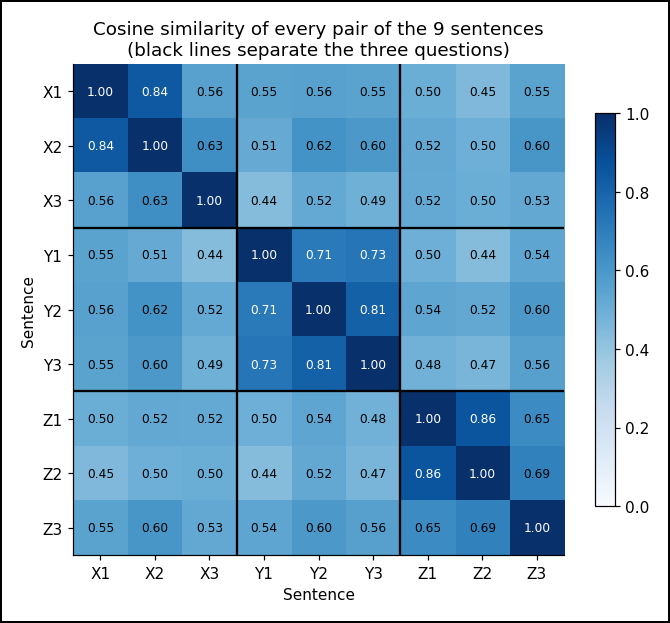

In [5]:
row_of = {s: i for i, s in enumerate(sentences["sentence"])}
small_vectors = vectors[[row_of[s] for s in small["sentence"]]]
grid = np.array([[cosine(a, b) for b in small_vectors] for a in small_vectors])

fig, ax = plt.subplots(figsize=(6.4, 5.4))
image = ax.imshow(grid, cmap="Blues", vmin=0, vmax=1)
for i in range(9):
    for j in range(9):
        ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if grid[i, j] > 0.7 else "black")
ax.set_xticks(range(9), labels)
ax.set_yticks(range(9), labels)
ax.set_xlabel("Sentence")
ax.set_ylabel("Sentence")
for k in (2.5, 5.5):
    ax.axhline(k, color="black", linewidth=1.5)
    ax.axvline(k, color="black", linewidth=1.5)
ax.grid(False)
ax.set_title("Cosine similarity of every pair of the 9 sentences\n(black lines separate the three questions)")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

In [6]:
same = np.equal.outer(small["question"].values, small["question"].values)
off_diagonal = ~np.eye(9, dtype=bool)
print("Pairs of different sentences of the same question:")
print(f"  Cosine similarity, lowest to highest = {grid[same & off_diagonal].min():.2f} to {grid[same & off_diagonal].max():.2f}")
print()
print("Pairs of sentences of different questions:")
print(f"  Cosine similarity, lowest to highest = {grid[~same].min():.2f} to {grid[~same].max():.2f}")

Pairs of different sentences of the same question:
  Cosine similarity, lowest to highest = 0.56 to 0.86

Pairs of sentences of different questions:
  Cosine similarity, lowest to highest = 0.44 to 0.62


**Observation:** the closest pairs sit inside the black squares, among sentences of the same question: sentences X1 and X2, both about Gemini's performance, scored 0.84, and sentences Z1 and Z2, both about Tyreek Hill's game against Washington, scored 0.86.

**Observation:** not every pair of the same question got close lists. Sentence X3 is listed for the Gemini question, but it is about a lawsuit against Google. It scored 0.56 with sentence X1 and 0.63 with sentence X2. Its higher score, 0.63, is about as high as the highest pair of different questions, 0.62. The dataset lists it for that question, and this module does not trace why. Being listed for the same question does not make two sentences about the same topic.

**Observation:** the three questions' topics have nothing in common, so their sentences' pairs might be expected near 0, the middle of the scale. None was: the lowest was 0.44. So the scores here cannot be read against the scale from −1 to 1 alone: 0.44 may be a low score for this model.

Step 3 checks both patterns across all 981 sentences: do sentences of the same question score higher, and do unrelated pairs stay well above 0?

## Step 3 of 4: every pair of sentences

**How much closer are the lists of sentences of the same question, across all sentences?** Every pair of two unique sentences gets a cosine similarity. The number of pairs:
- Each of the 981 sentences pairs with the 980 others: 981 × 980.
- That counts every pair twice (sentence 1 with sentence 2, and sentence 2 with sentence 1), so it is divided by 2.

The pairs are split into three groups:

| Group | Pairs in it |
|---|---|
| Same question | the two sentences are listed together for at least one question |
| Same category, different questions | both come from articles of the same category, such as two sports articles, but are never listed together for a question |
| Different categories | the two come from articles of different categories, and are never listed together for a question |

If embeddings work, the same-question pairs should score highest, the different-category pairs lowest, and the same-category pairs in between.

The last column of the table printed below takes the median of the same-question pairs, shown in that table's first row, and gives the share of each group's pairs that score above it. For the same-question pairs, that share is 50% by the definition of the median: it is the reference the other two groups are read against.

In [7]:
together = np.zeros((len(sentences), len(sentences)), dtype=bool)
for _, g in listed.groupby("question"):
    rows_ = [row_of[s] for s in g["sentence"].unique()]
    for a, b in itertools.permutations(rows_, 2):
        together[a, b] = True
category = sentences["category"].values
same_category = np.equal.outer(category, category)

similarity = vectors @ vectors.T / np.outer(np.linalg.norm(vectors, axis=1), np.linalg.norm(vectors, axis=1))
upper = np.triu_indices(len(sentences), k=1)
pairs = pd.DataFrame({"cosine": similarity[upper], "together": together[upper], "same category": same_category[upper]})
pairs["group"] = np.select([pairs["together"], pairs["same category"]],
                           ["Same question", "Same category, different questions"], "Different categories")

n_sent = len(sentences)
print("Pairs of two unique sentences = (sentences × (sentences − 1)) / 2")
print(f"  = ({n_sent:,} × {n_sent - 1:,}) / 2")
print(f"  = {len(pairs):,}")
print()

order = ["Same question", "Same category, different questions", "Different categories"]
same_q_median = pairs.loc[pairs["group"] == "Same question", "cosine"].median()
table = pd.DataFrame({
    "group": order,
    "pairs": [f"{(pairs['group'] == g).sum():,}" for g in order],
    "median cosine": [f"{pairs.loc[pairs['group'] == g, 'cosine'].median():.3f}" for g in order],
    "lowest": [f"{pairs.loc[pairs['group'] == g, 'cosine'].min():.3f}" for g in order],
    "highest": [f"{pairs.loc[pairs['group'] == g, 'cosine'].max():.3f}" for g in order],
    f"share above {same_q_median:.3f}": [f"{(pairs.loc[pairs['group'] == g, 'cosine'] > same_q_median).mean():.1%}" for g in order],
})
print("Cosine similarity of pairs of sentences, by group:")
print()
show(table)

Pairs of two unique sentences = (sentences × (sentences − 1)) / 2
  = (981 × 980) / 2
  = 480,690



Cosine similarity of pairs of sentences, by group:

group                                 pairs  median cosine  lowest  highest  share above 0.689
Same question                         1,253          0.689   0.468    0.996              50.0%
Same category, different questions  126,110          0.585   0.355    0.972               3.3%
Different categories                353,327          0.550   0.337    0.865               0.5%


The chart below shows how each group's pairs spread over the scores. Each group's curve is smoothed, and the area under it equals 1, so the three groups can be compared despite their very different sizes.

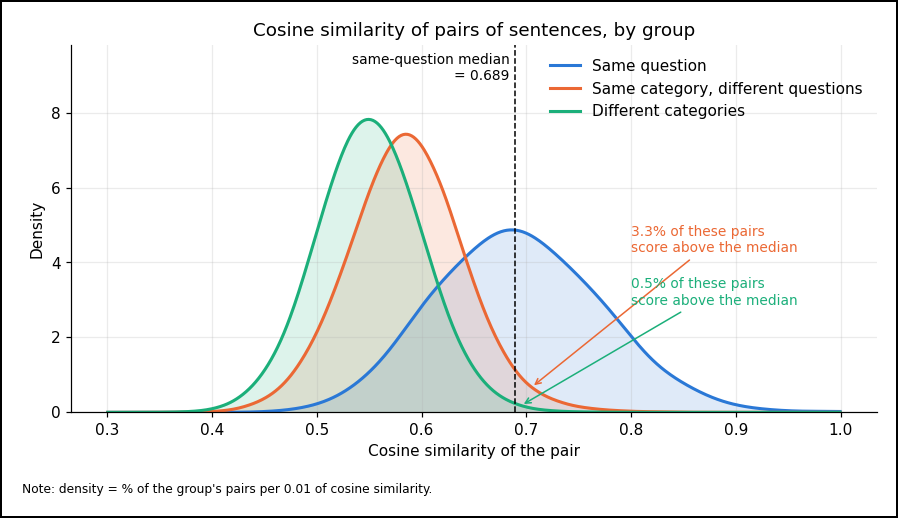

In [8]:
# Each curve: the share of the group's pairs in narrow bins (0.001 wide), smoothed with a
# Gaussian, and scaled so the area under the curve equals 1. The same-question group has
# far fewer pairs, so its curve is smoothed wider (0.025 instead of 0.01).
edges = np.arange(0.30, 1.0001, 0.001)
centres = (edges[:-1] + edges[1:]) / 2
curves = {}
fig, ax = plt.subplots(figsize=(8, 4.5))
for g, color, width in zip(order, [BLUE, ORANGE, AQUA], [0.025, 0.01, 0.01]):
    offsets = np.arange(-int(4 * width / 0.001), int(4 * width / 0.001) + 1)
    kernel = np.exp(-0.5 * (offsets * 0.001 / width) ** 2)
    kernel /= kernel.sum()
    values = pairs.loc[pairs["group"] == g, "cosine"]
    counts, _ = np.histogram(values, bins=edges)
    curves[g] = np.convolve(counts / (len(values) * 0.001), kernel, mode="same")
    ax.plot(centres, curves[g], color=color, linewidth=2, label=g)
    ax.fill_between(centres, curves[g], color=color, alpha=0.15)
ax.axvline(same_q_median, color="black", linestyle="--", linewidth=1)
ax.set_ylim(0, 9.8)
ax.text(same_q_median - 0.005, 9.6, f"same-question median\n= {same_q_median:.3f}", ha="right", va="top", fontsize=9)
for g, color, x_point, text_y in [("Same category, different questions", ORANGE, 0.705, 4.6),
                                  ("Different categories", AQUA, 0.695, 3.2)]:
    share = (pairs.loc[pairs["group"] == g, "cosine"] > same_q_median).mean()
    y_point = np.interp(x_point, centres, curves[g])
    ax.annotate(f"{share:.1%} of these pairs\nscore above the median", xy=(x_point, y_point), xytext=(0.80, text_y),
                color=color, fontsize=9, va="center",
                arrowprops=dict(arrowstyle="->", color=color, linewidth=1))
ax.set_xlabel("Cosine similarity of the pair")
ax.set_ylabel("Density")
ax.set_title("Cosine similarity of pairs of sentences, by group")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(rect=(0, 0.05, 1, 1))
fig.text(0.01, 0.015, "Note: density = % of the group's pairs per 0.01 of cosine similarity.", fontsize=8, ha="left")
plt.show()

**Observation:** the same-question pairs scored highest, the same-category pairs next, and the different-category pairs lowest, as expected. The same-question median, 0.689, is 0.104 above the same-category median, 0.585, and 0.139 above the different-category median, 0.550. Few pairs of the other two groups reach the same-question median: 3.3% of the same-category pairs and 0.5% of the different-category pairs.

**Observation:** the groups still overlap. Between about 0.55 and 0.70, the chart shows pairs of all three groups. So a score in that range, on its own, cannot tell whether two sentences belong to the same question.

**Hypothesis:** part of the overlap comes from pairs like sentences X1 and X3 in Step 2: listed for the same question, but about different topics. This module does not count how many such pairs there are.

**Observation:** the lowest score of all 480,690 pairs was 0.337, far above 0, though 353,327 of the pairs come from articles of different categories.

**Conclusion:** sentences of the same question get closer lists, on average, but the groups overlap, so a single score says little on its own: it means something only next to the scores of other pairs.

## Step 4 of 4: changes to a sentence's facts

**Does the embedding notice when a sentence's facts change?** Four sentences, tests 1 to 4, were chosen by hand from the listed sentences: each one names a person, team or company, and holds a number. Each one is then changed by hand in four ways:

| Change | What it does to the facts |
|---|---|
| Reworded | different words, same facts |
| Added "not" | the opposite fact, almost the same words |
| Other name | a different person, team or company, otherwise the same words |
| Other number | a different number, otherwise the same words |

Each changed sentence is compared with its original. If embeddings captured the facts, the pair of the original and its reworded sentence should score highest, and the original's pairs with the other three lower.

In [9]:
changes = pd.DataFrame([
    ["The size of Microsoft’s investment is believed to be around $10 billion, a figure we confirmed with our source.",
     "Our source confirmed that Microsoft put roughly ten billion dollars into the deal.",
     "The size of Microsoft’s investment is not believed to be around $10 billion, a figure we confirmed with our source.",
     "The size of Google’s investment is believed to be around $10 billion, a figure we confirmed with our source.",
     "The size of Microsoft’s investment is believed to be around $90 billion, a figure we confirmed with our source."],
    ["Murray is trying to restart his momentum after a disappointing 2023 where he slipped to world No.42.",
     "After a poor 2023 in which his ranking fell to 42nd in the world, Murray wants to get back on track.",
     "Murray is not trying to restart his momentum after a disappointing 2023 where he slipped to world No.42.",
     "Federer is trying to restart his momentum after a disappointing 2023 where he slipped to world No.42.",
     "Murray is trying to restart his momentum after a disappointing 2023 where he slipped to world No.2."],
    ["If you bet $130 on the Cowboys and they win, you would earn a profit of $100.",
     "A winning $130 wager on Dallas pays $100 in profit.",
     "If you bet $130 on the Cowboys and they do not win, you would earn a profit of $100.",
     "If you bet $130 on the Eagles and they win, you would earn a profit of $100.",
     "If you bet $130 on the Cowboys and they win, you would earn a profit of $900."],
    ["Apple has already indicated that it plans to appeal, but appealing is a lengthy process that can take around 18 months.",
     "Apple says it will appeal, though an appeal can drag on for about a year and a half.",
     "Apple has already indicated that it does not plan to appeal, but appealing is a lengthy process that can take around 18 months.",
     "Samsung has already indicated that it plans to appeal, but appealing is a lengthy process that can take around 18 months.",
     "Apple has already indicated that it plans to appeal, but appealing is a lengthy process that can take around 3 months."],
], columns=["original", "reworded", "added \"not\"", "other name", "other number"], index=[1, 2, 3, 4])
assert changes["original"].isin(sentences["sentence"]).all()

for letter, row in changes.iterrows():
    print(f"Test {letter}:")
    for column, text in row.items():
        print(f"  {column + ':':14} {text}")
    print()

Test 1:
  original:      The size of Microsoft’s investment is believed to be around $10 billion, a figure we confirmed with our source.
  reworded:      Our source confirmed that Microsoft put roughly ten billion dollars into the deal.
  added "not":   The size of Microsoft’s investment is not believed to be around $10 billion, a figure we confirmed with our source.
  other name:    The size of Google’s investment is believed to be around $10 billion, a figure we confirmed with our source.
  other number:  The size of Microsoft’s investment is believed to be around $90 billion, a figure we confirmed with our source.

Test 2:
  original:      Murray is trying to restart his momentum after a disappointing 2023 where he slipped to world No.42.
  reworded:      After a poor 2023 in which his ranking fell to 42nd in the world, Murray wants to get back on track.
  added "not":   Murray is not trying to restart his momentum after a disappointing 2023 where he slipped to world No.42.
  other 

In [10]:
scores = []
for letter, row in changes.iterrows():
    v = common.embed(row.tolist(), prefix="search_document: ")
    scores.append([f"{letter}"] + [f"{cosine(v[0], v[k]):.3f}" for k in range(1, 5)])
scores = pd.DataFrame(scores, columns=["test", "reworded", "added \"not\"", "other name", "other number"])
print("Cosine similarity of each changed sentence with its original:")
print()
show(scores)
print()
print("1.000 is rounded: no changed sentence scores exactly 1.")
print(f"For scale: the median same-question pair in Step 3 = {same_q_median:.3f}")

Cosine similarity of each changed sentence with its original:

test  reworded  added "not"  other name  other number
   1     0.844        0.999       0.851         1.000
   2     0.950        0.997       0.884         0.984
   3     0.873        0.991       0.854         0.999
   4     0.946        0.995       0.876         0.999

1.000 is rounded: no changed sentence scores exactly 1.
For scale: the median same-question pair in Step 3 = 0.689


**Observation:** adding "not" and changing a number left every sentence at 0.98 or above, closer to its original than any reworded sentence, though they state a different fact.

**Observation:** a swapped name moved the list more than "not" or a changed number: it scored lower than the rewording in tests 2, 3 and 4, and slightly higher in test 1. Every swapped name still scored above 0.85, far above the median same-question pair.

**Hypothesis:** an embedding follows mostly the words that carry the topic. "Not" and a number are common tokens that say little about the topic, so adding "not" or changing a number barely moves the list. A name is a rarer token, tied to one story, so swapping it moves the list more, even when the topic stays, as with Murray and Federer in tennis. The training described in the Lesson rewarded close lists for texts that belong together, which gave the model no direct reason to push apart two sentences that differ by one word.

**Conclusion:** no, not for "not" or a changed number: the embedding barely noticed them. A swapped name moved the list as much as a rewording that kept the facts, or more.

## Key takeaways

- An embedding model turns any text into an embedding, a list of numbers of a fixed size: 768 numbers for nomic-embed-text.
- Cosine similarity measures how close two embeddings point, from −1 to 1.
- Sentences listed for the same question got closer embeddings, on average, than other pairs. But the groups overlapped, and no pair scored near 0, so a score means something only next to other scores.
- A sentence with "not" added, or with a number changed, got almost the same embedding as its original. A swapped name moved the embedding as much as a rewording that kept the facts, or more.
- So in these four tests, a sentence with the opposite fact or the wrong number got a closer embedding than a correct rewording: a search that compares embeddings would rank it higher.

## Conclusion

Sentences about the same topic get close embeddings, so a search can find them by comparing embeddings, but embeddings do not check facts: a sentence with "not" added, or with a wrong number, gets almost the same embedding as the original.